Group members:
- Sang Nguyen
- Pan Mengqiao


#LUNA dataset: Data Analysis
This notebook checks the tables, images and masks in this project.

- A full CT can show several lung nodules. A VOI is a smaller 3D image cut around one nodule.
- A mask marks which voxels belong to the nodule. Each picture shows one 2D slice.
- The nodule table has one row per nodule. The annotation table has several sets of doctors' scores for each nodule.
- `Diagnosis` follows a rule based on these scores. It is not a result from a tissue test.

**Contents:**

1. Load data
2. Check the data
3. Nodule labels and features
4. Annotation and label analysis
5. Image and mask analysis
6. Feature engineering

Packages: pandas, numpy, matplotlib, nibabel, openpyxl and scipy.


## 1. Load data

### 1.1 Tables and image files

Read the two Excel files and find the image and mask files.

In [242]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
from scipy import ndimage
from IPython.display import display, HTML

In [243]:
# Read the two tables.
root = Path.cwd()
nodules = pd.read_excel(root / 'MetadatabyNoduleMaxVoting.xlsx')
annotations = pd.read_excel(root / 'MetadatabyAnnotation.xlsx')
keys = ['patient_id', 'nodule_id', 'seriesuid']
print('Nodules:', len(nodules))
print('Annotations:', len(annotations))
display(nodules.head())
display(annotations.head())

Nodules: 996
Annotations: 3674


,patient_id,nodule_id,seriesuid,coordX,coordY,coordZ,diameter_mm,bboxLowX,bboxLowY,bboxLowZ,...,Margin_value,Sphericity,Sphericity_value,Spiculation,Spiculation_value,Subtlety,Subtlety_value,Texture,Texture_value,len_mal_details
0,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,4,Ovoid,3,Marked Spiculation,5,Obvious,5,Solid,5,4
1,LIDC-IDRI-0003,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.170706757615...,72.286707,76.900239,-190.458928,21.453729,57.488893,63.984216,-199.0,...,3,Ovoid/Round,4,Nearly No Spiculation,2,Obvious,5,Solid/Mixed,4,4
2,LIDC-IDRI-0003,3,1.3.6.1.4.1.14519.5.2.1.6279.6001.170706757615...,23.490831,-47.633906,-172.279142,8.785833,17.293604,-51.679780,-176.5,...,4,Ovoid/Linear,2,No Spiculation,1,Fairly Subtle,3,Solid,5,4
3,LIDC-IDRI-0003,4,1.3.6.1.4.1.14519.5.2.1.6279.6001.170706757615...,-47.402846,-30.171209,-169.623946,12.823120,-54.893854,-37.734475,-174.0,...,5,Ovoid/Round,4,No Spiculation,1,Moderately Obvious,4,Solid,5,4
4,LIDC-IDRI-0004,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.323541312620...,-118.051233,94.754141,-230.190551,4.560710,-121.327297,91.802848,-232.5,...,5,Ovoid/Linear,2,No Spiculation,1,Moderately Subtle,2,Solid,5,4


,patient_id,nodule_id,seriesuid,coordX,coordY,coordZ,diameter_mm,bboxLowX,bboxLowY,bboxLowZ,...,Margin_value,Sphericity,Sphericity_value,Spiculation,Spiculation_value,Subtlety,Subtlety_value,Texture,Texture_value,len_mal_details
0,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,3,Ovoid,3,Near Marked Spiculation,4,Obvious,5,Solid,5,4
1,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,4,Ovoid/Round,4,Marked Spiculation,5,Obvious,5,Solid,5,4
2,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,2,Ovoid,3,Medium Spiculation,3,Obvious,5,Solid,5,4
3,LIDC-IDRI-0001,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.179049373636...,56.208405,86.343413,-115.867579,23.350644,43.531250,68.768753,-125.0,...,4,Round,5,Marked Spiculation,5,Obvious,5,Solid/Mixed,4,4
4,LIDC-IDRI-0003,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.170706757615...,72.286707,76.900239,-190.458928,21.453729,57.488893,63.984216,-199.0,...,3,Ovoid,3,Nearly No Spiculation,2,Obvious,5,Part Solid/Mixed,3,4


In [244]:
# Match each file name to its path.
image_dir = root / 'VOIs/VOIs/image'
mask_dir = root / 'VOIs/VOIs/nodule_mask'
images = {}
masks = {}
for path in sorted(image_dir.glob('*.nii.gz')):
    images[path.name] = path
for path in sorted(mask_dir.glob('*.nii.gz')):
    masks[path.name] = path

nodule_number = nodules['nodule_id'].astype(str)
nodules['image'] = nodules['patient_id'] + '_R_' + nodule_number + '.nii.gz'

### 1.2 Show CT and VOI images

- Example: LIDC-IDRI-0001. Show the middle VOI slice and the same position in the CT.
- Both files are 3D images. Each picture shows one slice.

In [245]:
# Read the example and turn both images to the same axis directions.
ct = nib.load(root / 'CT/CT/image/LIDC-IDRI-0001.nii.gz')
voi = nib.load(image_dir / 'LIDC-IDRI-0001_R_1.nii.gz')
ct = nib.as_closest_canonical(ct)
voi = nib.as_closest_canonical(voi)

# Find the same slice position in the CT.
voi_z = voi.shape[2] // 2
world = nib.affines.apply_affine(voi.affine, [0, 0, voi_z])
ct_inverse = np.linalg.inv(ct.affine)
ct_position = nib.affines.apply_affine(ct_inverse, world)
ct_z = int(round(ct_position[2]))
print('CT shape:', ct.shape, '| VOI shape:', voi.shape)

CT shape: (512, 512, 133) | VOI shape: (53, 64, 11)


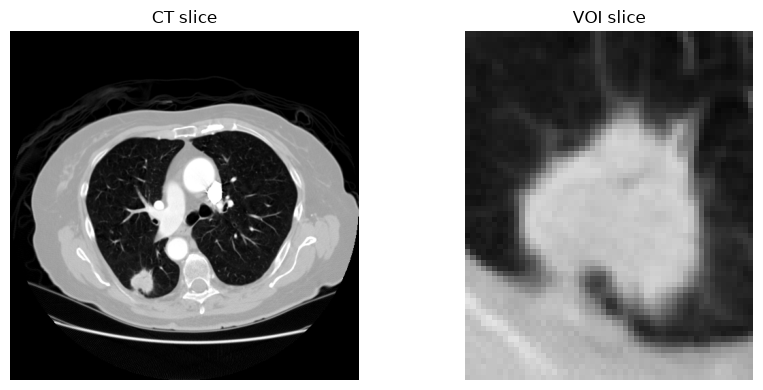

In [246]:
volumes = [ct, voi]
slices = [ct_z, voi_z]
titles = ['CT slice', 'VOI slice']
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for i in range(2):
    img = volumes[i]
    spacing = img.header.get_zooms()
    picture = np.asarray(img.dataobj[:, :, slices[i]]).T
    axes[i].imshow(
        picture,
        cmap='gray',
        origin='lower',
        vmin=-1000,
        vmax=400,
        aspect=spacing[1] / spacing[0]
    )
    axes[i].set_title(titles[i])
    axes[i].axis('off')
plt.tight_layout()
plt.show()

### 1.3 Voxel numbers in this project

We have **994 VOI images**. Each includes a nodule and some tissue around it.
These numbers come from the image files and the checks in Section 5.

| Item | Result |
|---|---|
| Shape along each axis | X: 43-91, Y: 43-109, Z: 2-62 voxels |
| Voxel count per VOI | 3,698-352,000 |
| Voxel count in all 994 VOIs | 20,405,061, including tissue around the nodules |
| Middle spacing (median), X, Y, Z | About 0.70 x 0.70 x 1.25 mm; each file can have different spacing |

- The largest VOI is `LIDC-IDRI-0141_R_1.nii.gz`: `80 x 80 x 55 = 352,000` voxels. This includes tissue around the nodule.
- The example below has **37,312 voxels**; its mask marks **6,547** as part of the nodule.
- Its spacing is `0.703125 x 0.703125 x 2.5 mm`. The nodule volume is about **8,091.84 mm3**.
- Use the mask to compare image values inside and outside the nodule.
- Use mask voxel count and spacing to find the nodule volume in mm3.
- Voxel counts alone do not tell us the size in mm3, because spacing differs between files.

In [247]:
# Count voxels in the example image and mask.
spacing = voi.header.get_zooms()[:3]
mask_img = nib.load(mask_dir / 'LIDC-IDRI-0001_R_1.nii.gz')
sample_mask = mask_img.get_fdata() > 0
total_voxels = int(np.prod(voi.shape))
nodule_voxels = int(sample_mask.sum())
voxel_volume = float(np.prod(spacing))
nodule_volume = nodule_voxels * voxel_volume

print('Shape (X, Y, Z):', voi.shape)
print('Spacing (X, Y, Z):', np.round(spacing, 3))
print('Spatial unit:', voi.header.get_xyzt_units()[0])
print('Total VOI voxels:', total_voxels)
print('Nodule voxels:', nodule_voxels)
print('Nodule volume (mm3):', round(nodule_volume, 2))

Shape (X, Y, Z): (53, 64, 11)
Spacing (X, Y, Z): [0.703 0.703 2.5  ]
Spatial unit: mm
Total VOI voxels: 37312
Nodule voxels: 6547
Nodule volume (mm3): 8091.84


## 2. Check the data

### 2.1 Missing values and repeated rows

Check both tables for empty cells and rows that appear more than once.

- Several annotation rows can refer to the same nodule because it has several sets of scores.

In [248]:
# Dataset size
print('Nodules:', len(nodules))
print('Annotations:', len(annotations))
print('Patients:', nodules['patient_id'].nunique())
print('CT series:', nodules['seriesuid'].nunique())

# Missing values
print('Missing values in nodules:', nodules.isna().sum().sum())
print('Missing values in annotations:', annotations.isna().sum().sum())

# Duplicate rows and keys
print('Duplicate nodule rows:', nodules.duplicated().sum())
print('Duplicate annotation rows:', annotations.duplicated().sum())
print('Duplicate nodule keys:', nodules.duplicated(keys).sum())
print('Repeated annotation keys:', annotations.duplicated(keys).sum())

Nodules: 996
Annotations: 3674
Patients: 551
CT series: 552
Missing values in nodules: 0
Missing values in annotations: 0
Duplicate nodule rows: 0
Duplicate annotation rows: 0
Duplicate nodule keys: 0
Repeated annotation keys: 2677


### 2.2 Check values

Check the score codes, nodule sizes and box coordinates.

- The Low/High names may follow voxel order rather than the smallest/largest coordinate in mm.

In [249]:
# Allowed scores from the PDF.
limits = {
    'Malignancy': 5,
    'Calcification': 6,
    'InternalStructure': 4,
    'Lobulation': 5,
    'Margin': 5,
    'Sphericity': 5,
    'Spiculation': 5,
    'Subtlety': 5,
    'Texture': 5
}
invalid_labels = ~nodules['Diagnosis_value'].isin([0, 1])
print('Invalid diagnosis codes:', invalid_labels.sum())
for name, table in [('Nodules', nodules), ('Annotations', annotations)]:
    print(name)
    for feature, maximum in limits.items():
        values = table[feature + '_value']
        invalid = ~values.isin(range(1, maximum + 1))
        print('Invalid ' + feature + ' codes:', invalid.sum())

Invalid diagnosis codes: 0
Nodules
Invalid Malignancy codes: 0
Invalid Calcification codes: 0
Invalid InternalStructure codes: 0
Invalid Lobulation codes: 0
Invalid Margin codes: 0
Invalid Sphericity codes: 0
Invalid Spiculation codes: 0
Invalid Subtlety codes: 0
Invalid Texture codes: 0
Annotations
Invalid Malignancy codes: 0
Invalid Calcification codes: 0
Invalid InternalStructure codes: 0
Invalid Lobulation codes: 0
Invalid Margin codes: 0
Invalid Sphericity codes: 0
Invalid Spiculation codes: 0
Invalid Subtlety codes: 0
Invalid Texture codes: 0


In [250]:
# Check size, number cells and box coordinates.
for name, table in [('Nodules', nodules), ('Annotations', annotations)]:
    print(name)
    print('Diameter <= 0:', (table['diameter_mm'] <= 0).sum())
    numeric = table.select_dtypes('number')
    print('Non-finite numeric values:', (~np.isfinite(numeric)).sum().sum())
    for axis in ['X', 'Y', 'Z']:
        low = table['bboxLow' + axis]
        high = table['bboxHigh' + axis]
        print(axis + ' reversed bounds:', (low > high).sum())
        print(axis + ' equal bounds:', (low == high).sum())

Nodules
Diameter <= 0: 0
Non-finite numeric values: 0
X reversed bounds: 22
X equal bounds: 0
Y reversed bounds: 22
Y equal bounds: 0
Z reversed bounds: 0
Z equal bounds: 2
Annotations
Diameter <= 0: 0
Non-finite numeric values: 0
X reversed bounds: 86
X equal bounds: 0
Y reversed bounds: 86
Y equal bounds: 0
Z reversed bounds: 0
Z equal bounds: 7


In [251]:
# Show five rows with reversed X or Y bounds.
reversed_x = nodules['bboxLowX'] > nodules['bboxHighX']
reversed_y = nodules['bboxLowY'] > nodules['bboxHighY']
reversed_boxes = nodules[reversed_x | reversed_y]
box_columns = [
    'patient_id',
    'nodule_id',
    'bboxLowX',
    'bboxHighX',
    'bboxLowY',
    'bboxHighY'
]
display(reversed_boxes[box_columns].head(5).round(2))

,patient_id,nodule_id,bboxLowX,bboxHighX,bboxLowY,bboxHighY
347,LIDC-IDRI-0262,1,104.04,91.50,33.11,23.08
388,LIDC-IDRI-0311,2,62.73,49.45,-35.94,-50.00
392,LIDC-IDRI-0313,1,-111.61,-144.57,1.76,-26.99
465,LIDC-IDRI-0415,1,115.13,107.86,-33.30,-41.17
466,LIDC-IDRI-0415,3,123.00,115.13,-7.27,-15.74


**Results**

- All checked codes are valid. Diameters are positive, and numeric values have no NaN or infinity.
- **22 nodules** have reversed X/Y bounds. The **86 flagged annotation rows** describe these same 22 nodules. All 22 VOIs have RAS voxel-axis directions.
- Their box corners are ordered when converted back to voxel coordinates. This suggests a coordinate-direction convention, rather than confirmed box errors. RAS alone does not mean bounds must be reversed.
- **2 nodule rows and 7 annotation rows** have equal Z bounds. These still need review before using the boxes to crop images.
- Keep the rows; these flags alone are not enough to remove them.

### 2.3 Count files and find missing images

Compare the image files with the table to find missing images and masks.

- A full CT can show several nodules. Each VOI is cut around one nodule.

In [252]:
# Count local files.
ct_files = list((root / 'CT/CT/image').glob('*.nii.gz'))
ct_mask_files = list((root / 'CT/CT/nodule_mask').glob('*.nii.gz'))
print('CT volumes:', len(ct_files))
print('CT masks:', len(ct_mask_files))
print('VOI images:', len(images))
print('VOI masks:', len(masks))

# Find metadata rows without matching files.
missing_images = nodules[~nodules['image'].isin(images.keys())]
missing_masks = nodules[~nodules['image'].isin(masks.keys())]
print('Missing VOI images:', len(missing_images))
print('Missing VOI masks:', len(missing_masks))
display(missing_images[['patient_id', 'nodule_id', 'Diagnosis', 'image']])

CT volumes: 3
CT masks: 6
VOI images: 994
VOI masks: 996
Missing VOI images: 2
Missing VOI masks: 0


,patient_id,nodule_id,Diagnosis,image
977,LIDC-IDRI-1002,1,Malign,LIDC-IDRI-1002_R_1.nii.gz
978,LIDC-IDRI-1002,2,Malign,LIDC-IDRI-1002_R_2.nii.gz


**Results**

- The CT folders have **3 full CT images** and **6 nodule masks**. The table lists **552 CT series**,
  so many full CT files are not in this project folder.
- There are **994 VOI images** and **996 VOI masks** for **996 nodules**.
  All listed nodules have masks, but two have no VOI image.
- The missing images are for **nodules 1 and 2 of LIDC-IDRI-1002**. Both have the label `Malign`.
  Their table rows and masks are still here.

- Image checks use **994 nodules: 650 Benign and 344 Malign**.
- Table checks can use all **996 nodules: 650 Benign and 346 Malign**.
- Keep the two rows and report that their images are missing.

### 2.4 Count nodules and score records

- A patient can have several nodules. A nodule can have several score records.
- There is no doctor ID, so these rows cannot tell us the number of different doctors.

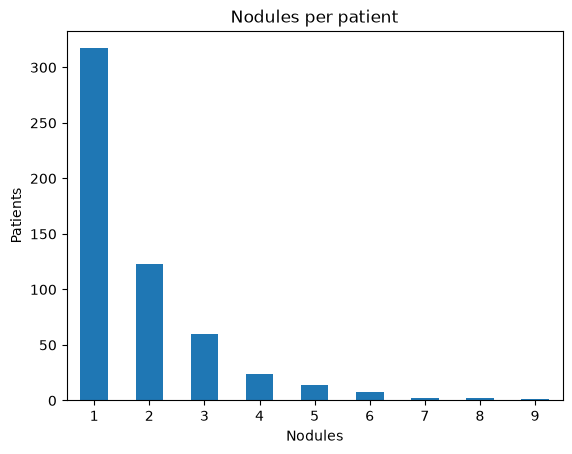

In [253]:
# Count nodules, then count patients with each nodule count.
nodules_per_patient = nodules.groupby('patient_id').size()
patient_counts = nodules_per_patient.value_counts()
patient_counts = patient_counts.sort_index()
patient_counts.plot.bar(
    title='Nodules per patient',
    xlabel='Nodules',
    ylabel='Patients',
    rot=0
)
plt.show()

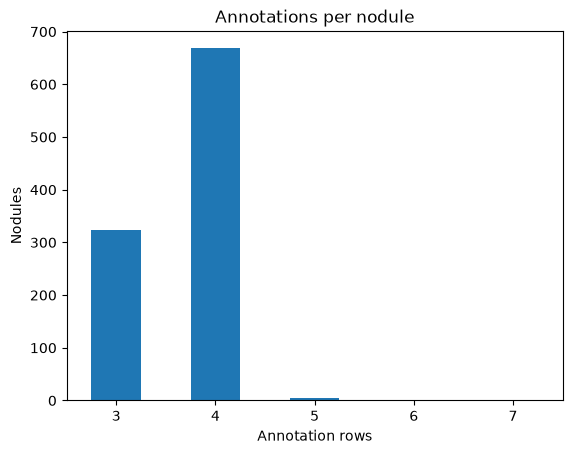

In [254]:
# Count score records for each nodule and CT.
annotations_per_nodule = annotations.groupby(keys).size()
annotation_counts = annotations_per_nodule.value_counts()
annotation_counts = annotation_counts.sort_index()
annotation_counts.plot.bar(
    title='Annotations per nodule',
    xlabel='Annotation rows',
    ylabel='Nodules',
    rot=0
)
plt.show()

**Results**

- **317 of 551 patients have one nodule**. Each patient has **1-9 nodules**.
- **323** nodule/CT pairs have **3 score records**, and **668** have **4**. Only **6** have 5-7 records.
- The score table has **997 nodule/CT pairs**. One is missing from the nodule table; Section 4 checks it.

## 3. Nodule labels and features

### 3.1 Count labels and scores

- A `Malignancy_value` score of **3** means the doctor was unsure about cancer.
- `Diagnosis` uses the individual scores. The one saved score is not enough to rebuild the label.

In [255]:
# Count labels and find their percentages.
counts = nodules['Diagnosis'].value_counts()
percent = (counts / len(nodules) * 100).round(1)
label_summary = pd.DataFrame({
    'count': counts,
    'percent': percent
})
display(label_summary)

score_labels = pd.crosstab(
    nodules['Malignancy_value'],
    nodules['Diagnosis']
)
display(score_labels)

,count,percent
Diagnosis,,
Benign,650,65.3
Malign,346,34.7


Diagnosis,Benign,Malign
Malignancy_value,,
1,154,8
2,183,32
3,313,51
4,0,119
5,0,136


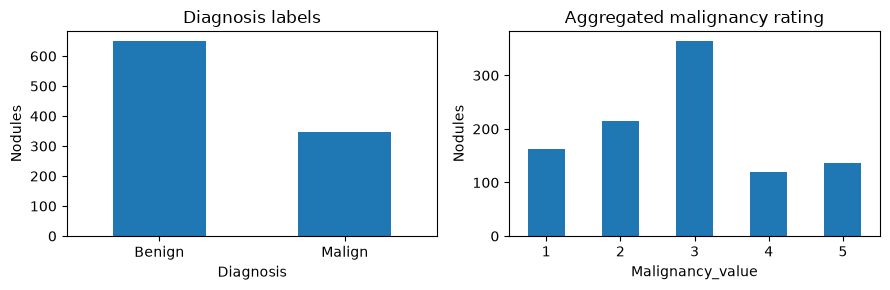

In [256]:
ratings = nodules['Malignancy_value'].value_counts()
ratings = ratings.sort_index()
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
counts.plot.bar(
    ax=axes[0],
    title='Diagnosis labels',
    rot=0
)
ratings.plot.bar(
    ax=axes[1],
    title='Aggregated malignancy rating',
    rot=0
)
for ax in axes:
    ax.set_ylabel('Nodules')
plt.tight_layout()
plt.show()

**Results**

- Benign nodules make up **65.3%** of the table, compared with **34.7% Malign**.
- Score **3** is the most common saved malignancy score (**364 nodules**); it means the assessment was unsure.
- The label uses individual votes, so the saved score alone does not explain every label.

### 3.2 Nodule sizes

Use the IQR rule to mark sizes far from the middle half of the data.

- A marked size may still be correct. Check it before removing the row.

In [257]:
# Mark unusually small or large sizes.
diameter = nodules['diameter_mm']
size_summary = nodules.groupby('Diagnosis')['diameter_mm'].describe()
display(size_summary.round(2))
q1, q3 = diameter.quantile([0.25, 0.75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
size_outliers = nodules[(diameter < lower) | (diameter > upper)]
print('IQR flags:', len(size_outliers))
print('Median diameter (mm):', round(diameter.median(), 2))
largest_outliers = size_outliers.nlargest(5, 'diameter_mm')
columns = keys + ['Diagnosis', 'diameter_mm']
display(largest_outliers[columns])

,count,mean,std,min,25%,50%,75%,max
Diagnosis,,,,,,,,
Benign,650.0,6.25,2.34,3.25,4.86,5.74,6.92,26.84
Malign,346.0,13.28,5.27,4.33,8.99,12.46,16.94,32.27


IQR flags: 66
Median diameter (mm): 6.77


,patient_id,nodule_id,seriesuid,Diagnosis,diameter_mm
99,LIDC-IDRI-0061,6,1.3.6.1.4.1.14519.5.2.1.6279.6001.287966244644...,Malign,32.270030
786,LIDC-IDRI-0772,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.112740418331...,Malign,30.610406
731,LIDC-IDRI-0697,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.943403138251...,Malign,27.442423
192,LIDC-IDRI-0139,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.481278873893...,Malign,27.075443
101,LIDC-IDRI-0064,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.487268565754...,Benign,26.837081


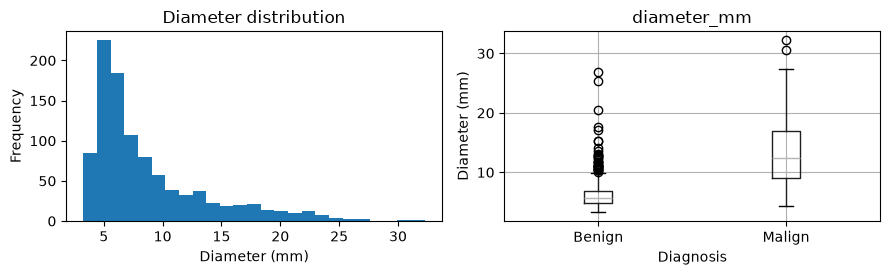

In [258]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
diameter.plot.hist(
    ax=axes[0],
    bins=25,
    title='Diameter distribution'
)
axes[0].set_xlabel('Diameter (mm)')
nodules.boxplot(
    column='diameter_mm',
    by='Diagnosis',
    ax=axes[1]
)
axes[1].set_ylabel('Diameter (mm)')
fig.suptitle('')
plt.tight_layout()
plt.show()

**Results**

- The median diameter is **6.77 mm**.
- The Malign group has a larger mean diameter (**13.28 vs 6.25 mm**), but the groups overlap.
- IQR flags **66 nodules above 18.26 mm: 63 Malign and 3 Benign**.
- These are large nodules, not confirmed data errors; keep them for review.

### 3.3 Correlations

- The heatmap shows Spearman correlations for all 22 numeric columns.
- The table ranks the 10 strongest positive pairs and 10 strongest negative pairs.
- **Positive:** values tend to rise together.
- **Negative:** one value tends to fall as the other rises.

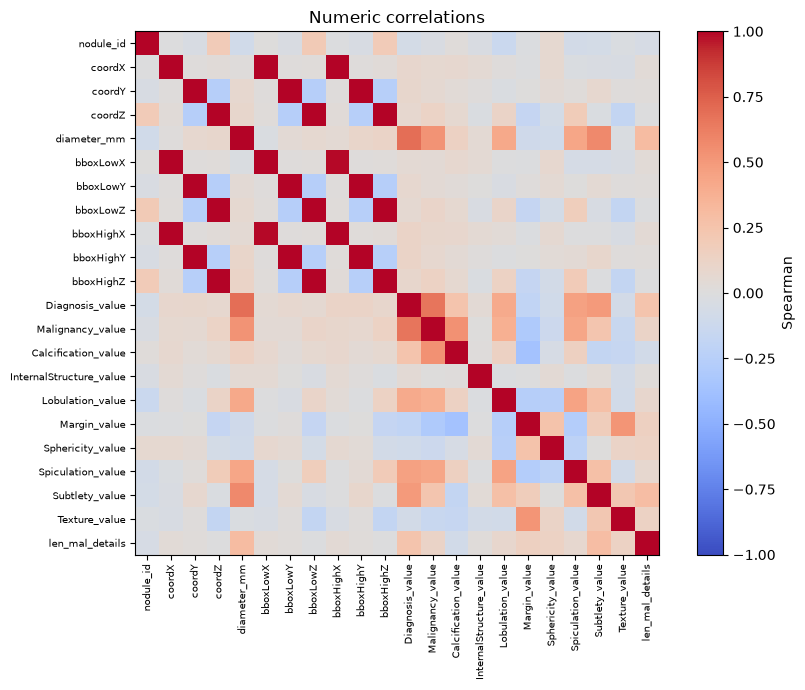

In [259]:
numeric = nodules.select_dtypes(include='number')
spearman = numeric.corr(method='spearman')

# Use the same scale for all columns.
plt.figure(figsize=(9, 7))
plt.imshow(spearman, cmap='coolwarm', vmin=-1, vmax=1)
plt.xticks(
    range(len(spearman)), spearman.columns,
    rotation=90, fontsize=7
)
plt.yticks(range(len(spearman)), spearman.index, fontsize=7)
plt.colorbar(label='Spearman')
plt.title('Numeric correlations')
plt.tight_layout()
plt.show()

In [260]:
# Keep each pair once and skip self-pairs.
features = list(spearman.columns)
rows = []
for i in range(len(features)):
    for j in range(i + 1, len(features)):
        first, second = features[i], features[j]
        rows.append([first, second, spearman.loc[first, second]])

correlations = pd.DataFrame(rows, columns=['Column 1', 'Column 2', 'Spearman'])
positive = correlations[correlations['Spearman'] > 0].nlargest(10, 'Spearman')
negative = correlations[correlations['Spearman'] < 0].nsmallest(10, 'Spearman')

positive['Sign'] = 'Positive'
negative['Sign'] = 'Negative'
positive['Rank'] = range(1, len(positive) + 1)
negative['Rank'] = range(1, len(negative) + 1)
ranking = pd.concat([positive, negative], ignore_index=True)
ranking = ranking[['Sign', 'Rank', 'Column 1', 'Column 2', 'Spearman']]
display(ranking.round(3))

,Sign,Rank,Column 1,Column 2,Spearman
0,Positive,1,coordZ,bboxHighZ,0.999
1,Positive,2,coordZ,bboxLowZ,0.999
2,Positive,3,coordY,bboxLowY,0.998
3,Positive,4,coordY,bboxHighY,0.998
4,Positive,5,coordX,bboxLowX,0.998
5,Positive,6,bboxLowZ,bboxHighZ,0.998
6,Positive,7,coordX,bboxHighX,0.998
7,Positive,8,bboxLowY,bboxHighY,0.994
8,Positive,9,bboxLowX,bboxHighX,0.992
9,Positive,10,diameter_mm,Diagnosis_value,0.694


**Results**

- Most top positive pairs are center and box coordinates. They describe the same location, so their correlations are close to **1**.
- `diameter_mm` and `Diagnosis_value` rank **10th** in the positive group (**0.694**).
- `Calcification_value` and `Margin_value` have the strongest negative correlation (**-0.360**). This is a small to moderate link; the calcification values are category codes.
- With `Malignancy_value`, `diameter_mm` has **0.527**, `Spiculation_value` **0.437**, and `Margin_value` **-0.301**.
- IDs, category codes and labels need care when reading these numbers. A correlation does not prove cause.

More details are in [EDA_results.md](EDA_results.md).

### 3.4 Feature distributions by diagnosis

Compare percentages within each label group, not raw counts.

- In each plot, the Benign bars add up to 100%; the Malign bars also add up to 100%.
- The table below explains the codes. Keep the original feature names from the Excel file.

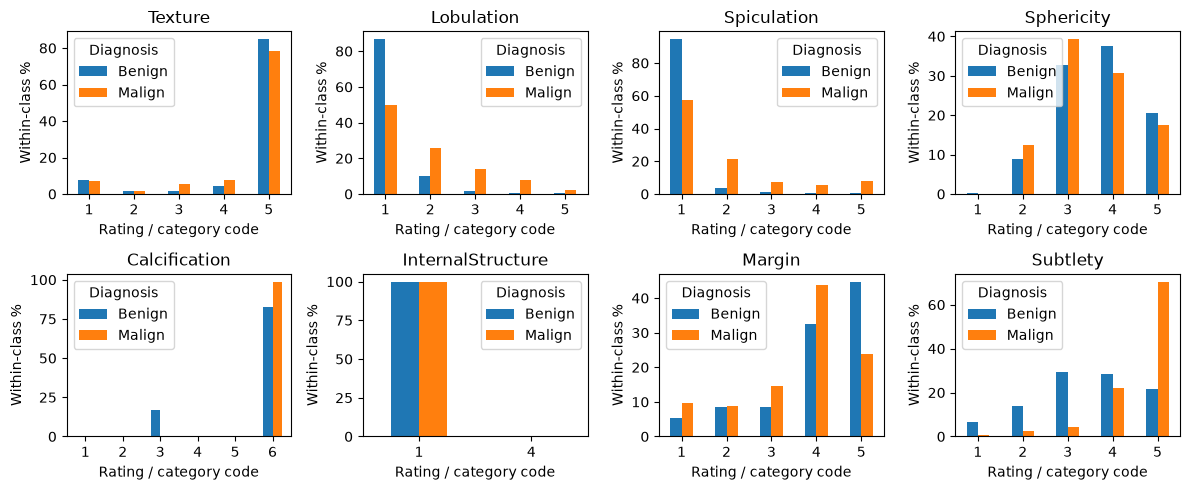

In [261]:
rating_features = [
    'Texture',
    'Lobulation',
    'Spiculation',
    'Sphericity',
    'Calcification',
    'InternalStructure',
    'Margin',
    'Subtlety'
]
fig, axes = plt.subplots(2, 4, figsize=(12, 5))
for feature, ax in zip(rating_features, axes.flat):
    percentages = pd.crosstab(
        nodules[feature + '_value'],
        nodules['Diagnosis'],
        normalize='columns'
    ) * 100
    percentages.plot.bar(
        ax=ax,
        title=feature,
        rot=0
    )
    ax.set(
        xlabel='Rating / category code',
        ylabel='Within-class %'
    )
plt.tight_layout()
plt.show()

**Results**

- Percentages are calculated separately for **650 Benign** and **346 Malign** nodules.
- Example: 94.6% means about 95 out of every 100 Benign nodules have the stated feature, not 94.6% of the whole dataset.

| Feature and code | Meaning | Benign (%) | Malign (%) |
|---|---|---:|---:|
| `Spiculation_value = 1` | No spiky edges | 94.6 | 57.5 |
| `Lobulation_value = 1` | No lobed edge (no rounded bumps) | 86.8 | 50.0 |
| `Texture_value = 5` | Solid | 84.9 | 78.3 |
| `Calcification_value = 6` | No calcification | 82.3 | 98.8 |
| `Margin_value = 5` | Sharp, clear edge | 44.8 | 23.7 |
| `Subtlety_value = 5` | Obvious / easy to see | 21.7 | 70.5 |
| `InternalStructure_value = 1` | Soft tissue | 100.0 | 99.7 |

**What this shows**

- The Benign group more often has no spikes or lobes, and a sharp edge.
- The Malign group more often has an obvious appearance and no calcification.
- Solid texture and soft-tissue structure are common in both groups. `Sphericity` scores also overlap.
- The groups share many values, so a single feature cannot fully separate the labels.
- Category codes such as `Calcification_value = 6` are names represented by numbers, not amounts.

### 3.5 Diameter distribution by diagnosis

Compare the shape of the diameter distributions, not just their averages.

- The histogram uses the same bins and percentages within each group, so the larger Benign group does not dominate.
- A positive `skew` means some large diameters stretch the right tail.
- The percentage at or below 10 mm is a simple example, not a prediction cutoff.

In [262]:
# Compare the middle, average and tail of each group.
size_data = nodules[['Diagnosis', 'diameter_mm']].copy()
size_data['at_most_10_mm'] = size_data['diameter_mm'] <= 10
size_groups = size_data.groupby('Diagnosis')
distribution_summary = size_groups['diameter_mm'].agg(['mean', 'median', 'skew'])
distribution_summary['at_most_10_mm_percent'] = size_groups['at_most_10_mm'].mean() * 100
display(distribution_summary.round(2))

,mean,median,skew,at_most_10_mm_percent
Diagnosis,,,,
Benign,6.25,5.74,3.33,94.77
Malign,13.28,12.46,0.66,32.37


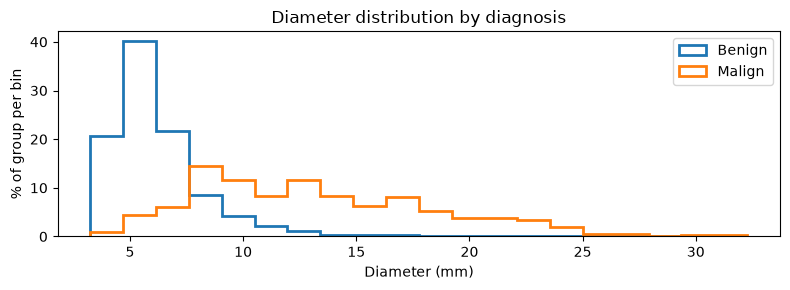

In [263]:
# Use common bins and compare percentages instead of counts.
bins = np.linspace(diameter.min(), diameter.max(), 21)
plt.figure(figsize=(8, 3))
for label in ['Benign', 'Malign']:
    values = nodules.loc[nodules['Diagnosis'] == label, 'diameter_mm']
    weights = np.ones(len(values)) * 100 / len(values)
    plt.hist(
        values,
        bins=bins,
        weights=weights,
        histtype='step',
        linewidth=2,
        label=label
    )
plt.xlabel('Diameter (mm)')
plt.ylabel('% of group per bin')
plt.title('Diameter distribution by diagnosis')
plt.legend()
plt.tight_layout()
plt.show()

**Results**

- Mean diameter is higher than the median in both groups. Some large nodules pull the average up.
- Skew is **3.33 for Benign** and **0.66 for Malign**. Most Benign nodules are small, with a few much larger ones.
- **94.8% of Benign** and **32.4% of Malign** nodules have diameter at or below **10 mm**.
- The two distributions overlap. Size is useful to explore, but cannot fully separate the labels.
- Large values are not automatically errors.

## 4. Annotation and label analysis

A nodule can have several score records. We check how these scores produce the label and how much they differ.

- **Label rule:** at least two records with `Malignancy_value > 3` means `Malign`. Otherwise, the label is `Benign`.
- **Example:** scores **1, 2, 5, 4** give `Malign` because **5 and 4** are above 3, even though the other two scores are low.
- Match records using `patient_id`, `nodule_id` and `seriesuid` so different scans stay separate.

In [264]:
# Collect scores for each nodule and CT.
votes = annotations.copy()
votes['high_vote'] = votes['Malignancy_value'] > 3
groups = votes.groupby(keys)
ratings = pd.DataFrame()
ratings['annotation_count'] = groups.size()
ratings['min_rating'] = groups['Malignancy_value'].min()
ratings['max_rating'] = groups['Malignancy_value'].max()
ratings['high_votes'] = groups['high_vote'].sum()
ratings['rating_range'] = ratings['max_rating'] - ratings['min_rating']
ratings = ratings.reset_index()

In [265]:
# Add one score summary to each nodule row.
checks = nodules.merge(
    ratings,
    on=keys,
    how='left',
    validate='one_to_one'
)
checks['expected_label'] = 'Benign'
checks.loc[checks['high_votes'] >= 2, 'expected_label'] = 'Malign'
missing_scores = checks['annotation_count'].isna()
checks.loc[missing_scores, 'expected_label'] = pd.NA

different_labels = checks['Diagnosis'] != checks['expected_label']
different_counts = checks['annotation_count'] != checks['len_mal_details']
print('Missing rating groups:', missing_scores.sum())
print('Label mismatches:', (~missing_scores & different_labels).sum())
print('Annotation count mismatches:', different_counts.sum())

Missing rating groups: 0
Label mismatches: 0
Annotation count mismatches: 0


In [266]:
# Find score groups that are missing from the nodule table.
extra = ratings.merge(
    nodules[keys],
    on=keys,
    how='left',
    indicator=True
)
extra_groups = extra[extra['_merge'] == 'left_only']
display(extra_groups[keys + ['annotation_count']])

,patient_id,nodule_id,seriesuid,annotation_count
401,LIDC-IDRI-0332,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.316900421002...,4


Identical ratings: 136
Rating range >= 3: 142


,patient_id,nodule_id,seriesuid,min_rating,max_rating,high_votes,Diagnosis
124,LIDC-IDRI-0081,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.172243743899...,1,5,2,Malign
186,LIDC-IDRI-0130,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.257515388956...,1,5,1,Benign
195,LIDC-IDRI-0141,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.267957701183...,1,5,2,Malign
348,LIDC-IDRI-0264,1,1.3.6.1.4.1.14519.5.2.1.6279.6001.262873069163...,1,5,1,Benign
349,LIDC-IDRI-0264,2,1.3.6.1.4.1.14519.5.2.1.6279.6001.262873069163...,1,5,2,Malign


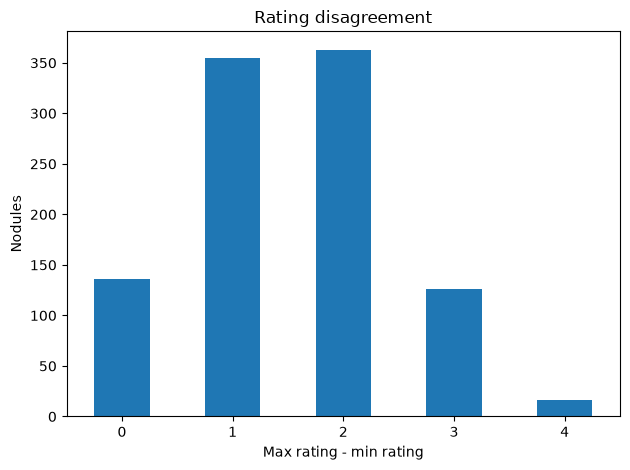

In [267]:
# Compare the highest and lowest scores.
same_scores = checks['rating_range'] == 0
large_gaps = checks['rating_range'] >= 3
print('Identical ratings:', same_scores.sum())
print('Rating range >= 3:', large_gaps.sum())
largest_gaps = checks.nlargest(5, 'rating_range')
columns = keys + ['min_rating', 'max_rating', 'high_votes', 'Diagnosis']
display(largest_gaps[columns])

gap_counts = checks['rating_range'].value_counts().sort_index()
gap_counts.plot.bar(
    title='Rating disagreement',
    xlabel='Max rating - min rating',
    ylabel='Nodules',
    rot=0
)
plt.tight_layout()
plt.show()

**Results**

- All **996 nodules** have score records. There are **0 label mismatches** and **0 record-count mismatches** with `len_mal_details`.
- The annotation table has **997 groups**. One extra group has **4 records** for **LIDC-IDRI-0332, nodule 1**, in another CT series, and is absent from the nodule table.
- **136 nodules (13.7%)** have identical scores. **142 (14.3%)** have a gap of at least 3 points between their lowest and highest scores.
- The saved labels follow the voting rule, but one final label does not show the differences between score records.
- The labels are based on assessments, not confirmed tissue-test results.

## 5. Image and mask analysis

We check the files, view examples and compare measurements between labels.

- A VOI contains the nodule and nearby tissue.
- Its mask marks nodule voxels with 1 and the rest with 0.

### 5.1 File checks and image sizes

- Check mask values and image values.
- Check whether each pair has the same shape and position (`affine`).
- Count mask parts in 3D. Touching faces, edges or corners count as connected.

In [268]:
# Read image size, spacing and values in one pass.
image_rows = []
for name, path in images.items():
    img = nib.load(path)
    data = img.get_fdata(dtype=np.float32)
    x, y, z = img.shape
    sx, sy, sz = img.header.get_zooms()[:3]
    image_rows.append({
        'image': name,
        'size_x': x,
        'size_y': y,
        'size_z': z,
        'spacing_x': sx,
        'spacing_y': sy,
        'spacing_z': sz,
        'total_voxels': int(np.prod(img.shape)),
        'orientation': ''.join(nib.aff2axcodes(img.affine)),
        'finite': bool(np.isfinite(data).all()),
        'min': data.min(),
        'max': data.max()
    })
image_stats = pd.DataFrame(image_rows)

In [269]:
# Count mask voxels, volume and separate parts.
mask_rows = []
for name, path in masks.items():
    img = nib.load(path)
    data = img.get_fdata(dtype=np.float32)
    mask = data > 0
    voxels = int(mask.sum())
    regions, components = ndimage.label(mask, structure=np.ones((3, 3, 3)))
    part_sizes = np.bincount(regions.ravel())[1:]
    largest_fraction = np.nan
    if voxels > 0:
        largest_fraction = part_sizes.max() / voxels
    voxel_volume = float(np.prod(img.header.get_zooms()[:3]))
    mask_rows.append({
        'image': name,
        'voxels': voxels,
        'volume_mm3': voxels * voxel_volume,
        'finite': bool(np.isfinite(data).all()),
        'binary': bool(np.isin(data, [0, 1]).all()),
        'components': components,
        'largest_fraction': largest_fraction
    })
mask_stats = pd.DataFrame(mask_rows)

In [270]:
# Match masks to images, then keep usable pairs.
mask_stats['has_image'] = mask_stats['image'].isin(images)
mask_stats['shape_ok'] = None
mask_stats['affine_ok'] = None
for name in images:
    if name not in masks:
        continue
    img = nib.load(images[name])
    mask_img = nib.load(masks[name])
    row = mask_stats['image'] == name
    mask_stats.loc[row, 'shape_ok'] = img.shape == mask_img.shape
    mask_stats.loc[row, 'affine_ok'] = np.allclose(img.affine, mask_img.affine)

valid_mask = mask_stats['finite'] & mask_stats['binary']
valid_mask = valid_mask & (mask_stats['voxels'] > 0)
same_shape = mask_stats['shape_ok'] == True
same_position = mask_stats['affine_ok'] == True
valid_pairs = mask_stats[valid_mask & same_shape & same_position].copy()

In [271]:
# Measure image values and add the labels.
intensity_rows = []
for name in valid_pairs['image']:
    data = nib.load(images[name]).get_fdata(dtype=np.float32)
    mask = nib.load(masks[name]).get_fdata() > 0
    if not np.isfinite(data).all():
        continue
    outside = data[~mask]
    outside_mean = np.nan
    if outside.size > 0:
        outside_mean = outside.mean()
    intensity_rows.append({
        'image': name,
        'inside_mean': data[mask].mean(),
        'inside_std': data[mask].std(),
        'outside_mean': outside_mean
    })
intensities = pd.DataFrame(intensity_rows)
image_labels = nodules[['image', 'patient_id', 'Diagnosis']]
intensities = intensities.merge(image_labels, on='image', how='left', validate='one_to_one')
volumes = mask_stats[['image', 'volume_mm3']]
analysis = intensities.merge(volumes, on='image', validate='one_to_one')

In [272]:
# Show the main checks and a small size/spacing table.
direction_counts = image_stats['orientation'].value_counts()
file_checks = pd.Series({
    'VOI images': len(image_stats),
    'VOI masks': len(mask_stats),
    'Usable image-mask pairs': len(analysis),
    'Masks without images': (~mask_stats['has_image']).sum(),
    'Empty or invalid masks': (~valid_mask).sum(),
    'Image/mask mismatches': ((mask_stats['shape_ok'] == False) | (mask_stats['affine_ok'] == False)).sum(),
    'Images with NaN or infinity': (~image_stats['finite']).sum(),
    'Pairs without labels': analysis['Diagnosis'].isna().sum(),
    'Masks with separate parts': (mask_stats['components'] > 1).sum(),
    'LPS images': direction_counts.get('LPS', 0),
    'RAS images': direction_counts.get('RAS', 0)
})
display(file_checks.to_frame('count'))
columns = [
    'size_x', 'size_y', 'size_z',
    'spacing_x', 'spacing_y', 'spacing_z', 'total_voxels'
]
display(image_stats[columns].agg(['min', 'median', 'max']).round(2))

,count
VOI images,994
VOI masks,996
Usable image-mask pairs,994
Masks without images,2
Empty or invalid masks,0
Image/mask mismatches,0
Images with NaN or infinity,0
Pairs without labels,0
Masks with separate parts,35
LPS images,972


,size_x,size_y,size_z,spacing_x,spacing_y,spacing_z,total_voxels
min,43.0,43.0,2.0,0.46,0.46,0.45,3698.0
median,44.0,44.0,6.0,0.70,0.70,1.25,11352.0
max,91.0,109.0,62.0,0.98,0.98,2.50,352000.0


**Results**

- **994 pairs** match; two masks have no image.
- All **996 masks** are nonempty, binary and finite; **35** have separate parts to review.
- VOIs have **2-62 slices** and **3,698-352,000 voxels**.
- Median spacing is **0.70 x 0.70 x 1.25 mm**. Z spacing is the distance between slices, not total nodule depth.
- The **972 LPS** and **22 RAS** images need a common input rule before training.
- Matching files does not prove every mask outline is correct.

### 5.2 View the masks

- Show one example per label, using the slice with the largest mask area.
- The orange outline marks the nodule.
- Spacing keeps the picture's shape correct.

In [273]:
# Get the image and mask from the same slice.
def read_nodule_slice(name):
    img = nib.as_closest_canonical(nib.load(images[name]))
    mask_img = nib.as_closest_canonical(nib.load(masks[name]))
    data = img.get_fdata()
    mask = mask_img.get_fdata() > 0
    z = int(mask.sum(axis=(0, 1)).argmax())
    spacing = img.header.get_zooms()
    return data[:, :, z].T, mask[:, :, z].T, spacing[1] / spacing[0]

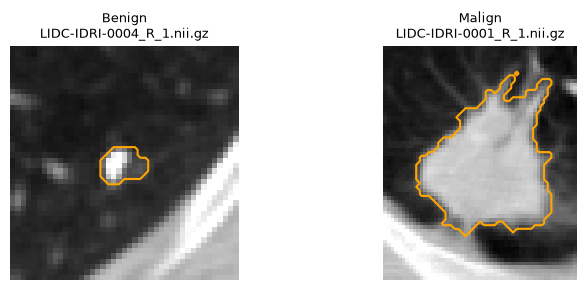

In [274]:
samples = analysis.groupby('Diagnosis').head(1).sort_values('Diagnosis')
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for i in range(len(samples)):
    row = samples.iloc[i]
    picture, mask_slice, aspect = read_nodule_slice(row['image'])
    ax = axes[i]
    ax.imshow(
        picture,
        cmap='gray',
        origin='lower',
        vmin=-1000,
        vmax=400
    )
    ax.contour(
        mask_slice,
        levels=[0.5],
        colors='orange'
    )
    ax.set_aspect(aspect)
    ax.set_title(f"{row['Diagnosis']}\n{row['image']}", fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

### 5.3 Compare the groups

- **Volume:** mask voxel count x voxel volume.
- **`inside_mean` and `inside_std`:** mean and spread of image values inside the nodule.
- **`outside_mean`:** mean image value in nearby tissue within the VOI.
- Each nodule contributes one row.
- These examples and plots do not check every mask; image-value units have not been confirmed as HU.

Diagnosis,Benign,Malign
volume_mm3,281.94,2541.27
inside_mean,-303.39,-265.87
inside_std,282.25,253.65
outside_mean,-655.61,-663.16


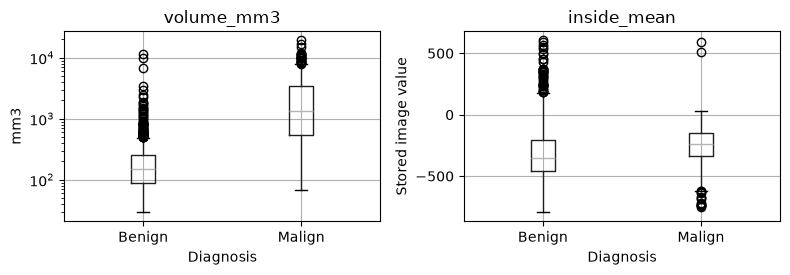

In [275]:
columns = ['volume_mm3', 'inside_mean', 'inside_std', 'outside_mean']
summary_stats = analysis.groupby('Diagnosis')[columns].mean()
display(summary_stats.T.round(2))

# Compare volume and average image value inside the mask.
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for column, ax in zip(['volume_mm3', 'inside_mean'], axes):
    analysis.boxplot(
        column=column,
        by='Diagnosis',
        ax=ax
    )
axes[0].set_yscale('log')
axes[0].set_ylabel('mm3')
axes[1].set_ylabel('Stored image value')
fig.suptitle('')
plt.tight_layout()
plt.show()

**Results**

- The image analysis uses **650 Benign** and **344 Malign** nodules.
- Mean mask volume is **281.94 vs 2,541.27 mm3** (Benign vs Malign).
- Mean `inside_mean` is **-303.39 vs -265.87** (Benign vs Malign).
- Malign nodules are larger on average, but the groups overlap.
- Size or image values alone cannot fully separate the labels.

## 6. Feature engineering

Create simple features using the 994 available image-mask pairs. Keep the original feature names.

### 6.1 Create new features

| Feature | Meaning |
|---|---|
| `log_volume` | Log of 1 + mask volume; compresses large values. |
| `intensity_difference` | Mean inside the mask minus mean outside it, within the VOI. |
| `inside_median` | Middle image value inside the nodule. |
| `inside_iqr` | Percentile 75 minus percentile 25 inside the nodule. |
| `mask_size_x_mm`, `mask_size_y_mm`, `mask_size_z_mm` | Width of the smallest box around the mask along each axis, using spacing. |
| `mask_fill_ratio` | Nodule voxel count divided by voxel count in that small box. |

- The sizes describe the mask, not the whole VOI.
- Turn masks to the same axis directions before measuring them. All mask parts are included in the box.
- These features need a nodule mask when used for predictions. The image files stay unchanged.

In [276]:
# Add the original diameter to the image measurements.
feature_data = analysis.merge(
    nodules[['image', 'diameter_mm']],
    on='image',
    validate='one_to_one'
)
feature_data['log_volume'] = np.log1p(feature_data['volume_mm3'])
feature_data['intensity_difference'] = (
    feature_data['inside_mean'] - feature_data['outside_mean']
)

In [277]:
# Measure the middle value and spread inside each mask.
rows = []
for name in feature_data['image']:
    data = nib.load(images[name]).get_fdata(dtype=np.float32)
    mask = nib.load(masks[name]).get_fdata() > 0
    inside = data[mask]
    q1, q3 = np.percentile(inside, [25, 75])
    rows.append([name, np.median(inside), q3 - q1])

extra_intensity = pd.DataFrame(
    rows,
    columns=['image', 'inside_median', 'inside_iqr']
)

In [278]:
# Use the mask's small box, including the end voxels.
rows = []
for name in feature_data['image']:
    img = nib.as_closest_canonical(nib.load(masks[name]))
    mask = img.get_fdata() > 0
    x, y, z = np.where(mask)
    size = np.array([
        x.max() - x.min() + 1,
        y.max() - y.min() + 1,
        z.max() - z.min() + 1
    ])
    size_mm = size * np.array(img.header.get_zooms()[:3])
    fill_ratio = mask.sum() / np.prod(size)
    rows.append([
        name, size_mm[0], size_mm[1], size_mm[2], fill_ratio
    ])

mask_features = pd.DataFrame(
    rows,
    columns=[
        'image', 'mask_size_x_mm', 'mask_size_y_mm',
        'mask_size_z_mm', 'mask_fill_ratio'
    ]
)

In [279]:
feature_data = feature_data.merge(extra_intensity, on='image', validate='one_to_one')
feature_data = feature_data.merge(mask_features, on='image', validate='one_to_one')
new_features = [
    'log_volume',
    'intensity_difference',
    'inside_median',
    'inside_iqr',
    'mask_size_x_mm',
    'mask_size_y_mm',
    'mask_size_z_mm',
    'mask_fill_ratio'
]
# Show three examples with features on separate rows.
display(feature_data[new_features].head(3).T.round(2))

,0,1,2
log_volume,9.00,9.21,6.32
intensity_difference,458.40,421.48,174.07
inside_median,-56.00,-455.00,-507.00
inside_iqr,486.00,578.00,455.00
mask_size_x_mm,28.83,35.27,13.12
mask_size_y_mm,35.16,31.17,9.02
mask_size_z_mm,22.50,25.00,10.00
mask_fill_ratio,0.35,0.36,0.47


### 6.2 Compare the new features

Show the mean and median for each label group.

- A group difference does not prove that a feature will improve a model.
- `inside_iqr` measures spread, not the average image value.
- `mask_fill_ratio` measures box occupancy; it does not directly measure roundness.

In [280]:
feature_summary = feature_data.groupby('Diagnosis')[new_features]
feature_summary = feature_summary.agg(['mean', 'median'])
display(feature_summary.T.round(2))

Diagnosis                    Benign  Malign
log_volume           mean      5.10    7.22
                     median    5.00    7.21
intensity_difference mean    352.22  397.29
                     median  300.47  406.05
inside_median        mean   -329.63 -223.23
                     median -360.00 -200.75
inside_iqr           mean    431.88  394.68
                     median  375.75  392.62
mask_size_x_mm       mean      8.06   19.22
                     median    7.12   16.41
mask_size_y_mm       mean      8.07   19.11
                     median    7.21   16.68
mask_size_z_mm       mean      7.19   15.51
                     median    6.25   15.00
mask_fill_ratio      mean      0.44    0.36
                     median    0.45    0.36

**Results**

- Mean `log_volume` is **5.10 for Benign** and **7.22 for Malign**. The log keeps the size order while compressing large values.
- Mean `intensity_difference` is **352.22 vs 397.29**. Values inside nodules are higher than nearby tissue on average.
- Mean `inside_median` is **-329.63 vs -223.23**; mean `inside_iqr` is **431.88 vs 394.68**. Median describes the middle value; IQR describes spread.
- Mean mask sizes (X, Y, Z) are **8.06, 8.07, 7.19 mm** for Benign and **19.22, 19.11, 15.51 mm** for Malign. The Malign group is larger along all three axes on average.
- Mean `mask_fill_ratio` is about **0.445 vs 0.356**. This is the fraction of each tight mask box filled by nodule voxels, not the fraction of the whole VOI.
- These differences do not prove better predictions.
- Log volume is not the same as scaling all features. Image values have not been confirmed as HU.

### 6.3 Prepare a feature table

Use eleven numeric features as a starting point.

- `X` holds the features; `y` holds the label (Benign = 0, Malign = 1).
- Keep patient IDs for a later split, but leave IDs and label-related columns out of `X`.
- `Malignancy_value` and vote counts help build the label, so they should not be inputs when predicting it.
- Use `log_volume` instead of adding both raw volume and log volume.
- Some features describe similar information; choose which to keep using the training data.

In [281]:
feature_columns = [
    'diameter_mm',
    'log_volume',
    'inside_mean',
    'inside_std',
    'intensity_difference',
    'inside_median',
    'inside_iqr',
    'mask_size_x_mm',
    'mask_size_y_mm',
    'mask_size_z_mm',
    'mask_fill_ratio'
]
X = feature_data[feature_columns].copy()
y = (feature_data['Diagnosis'] == 'Malign').astype(int)
patient_ids = feature_data['patient_id'].copy()

print('Feature table shape:', X.shape)
print('Missing values:', X.isna().sum().sum())
print('Non-finite values:', (~np.isfinite(X)).sum().sum())

Feature table shape: (994, 11)
Missing values: 0
Non-finite values: 0


**Results**

- `X` has **994 rows and 11 features**, with **0 missing values** and **0 non-finite values**.
- The two nodules without images are not included.
- The labels contain **650 Benign** and **344 Malign** nodules.
- Before training, split by patient so one patient's nodules stay in the same group.
- Fit scaling and choose features using the training group only.
- No model has been trained or tested here.